In [105]:
import pandas as pd
import matplotlib.pyplot as plt
from numpy import nan

In [106]:
df = pd.read_csv("eleicao_ficticia.csv")
display(df.head())

,secao,bairro,eleitores_aptos,abstencoes,votos_brancos,votos_nulos,votos_ana,votos_bruno,votos_carla
0,1,Centro,240,24,8,10,57,53,88
1,2,Centro,313,53,11,15,94,80,60
2,3,Centro,386,93,14,20,132,106,21
3,4,Centro,459,55,17,25,141,116,105
4,5,Centro,532,101,20,30,191,149,41


In [107]:
print("Dimesão da base:", df.shape)
display(df.head())
df.info()
secoes = df['secao']
bairro = df['bairro']
print("\nNúmero de secoes:", secoes.count())
print("Número de bairros:", bairro.nunique())

Dimesão da base: (24, 9)


,secao,bairro,eleitores_aptos,abstencoes,votos_brancos,votos_nulos,votos_ana,votos_bruno,votos_carla
0,1,Centro,240,24,8,10,57,53,88
1,2,Centro,313,53,11,15,94,80,60
2,3,Centro,386,93,14,20,132,106,21
3,4,Centro,459,55,17,25,141,116,105
4,5,Centro,532,101,20,30,191,149,41


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   secao            24 non-null     int64 
 1   bairro           24 non-null     object
 2   eleitores_aptos  24 non-null     int64 
 3   abstencoes       24 non-null     int64 
 4   votos_brancos    24 non-null     int64 
 5   votos_nulos      24 non-null     int64 
 6   votos_ana        24 non-null     int64 
 7   votos_bruno      24 non-null     int64 
 8   votos_carla      24 non-null     int64 
dtypes: int64(8), object(1)
memory usage: 1.8+ KB

Número de secoes: 24
Número de bairros: 4


In [108]:
quant_null_col = df.isna().sum()
quant_duplicated = df.duplicated().sum()
df_tratado = df.drop(columns=['bairro', 'secao'])
#display(df_tratado)
print("Quantidade de valores nulos:")
print(quant_null_col)
print("\n")
print("Todas as secoes são unicas: ",df['secao'].is_unique)
print("\n")
print("Quantidade de linhas duplicadas: ",quant_duplicated)

for chave in df_tratado.keys():
  print(f"Os(As) {chave} são inteiros não nulos maiores que 0")
  resultado = (df[chave].ge(0)) & (df[chave] % 1 == 0)
  print(resultado)
print("\n")
eleitores_maior_abstencao= df["abstencoes"] < df['eleitores_aptos']
print("Eleitores aptos é maior que abstentecao", eleitores_maior_abstencao)




Quantidade de valores nulos:
secao              0
bairro             0
eleitores_aptos    0
abstencoes         0
votos_brancos      0
votos_nulos        0
votos_ana          0
votos_bruno        0
votos_carla        0
dtype: int64


Todas as secoes são unicas:  True


Quantidade de linhas duplicadas:  0
Os(As) eleitores_aptos são inteiros não nulos maiores que 0
0     True
1     True
2     True
3     True
4     True
5     True
6     True
7     True
8     True
9     True
10    True
11    True
12    True
13    True
14    True
15    True
16    True
17    True
18    True
19    True
20    True
21    True
22    True
23    True
Name: eleitores_aptos, dtype: bool
Os(As) abstencoes são inteiros não nulos maiores que 0
0     True
1     True
2     True
3     True
4     True
5     True
6     True
7     True
8     True
9     True
10    True
11    True
12    True
13    True
14    True
15    True
16    True
17    True
18    True
19    True
20    True
21    True
22    True
23    True
Name: abstencoes,

In [109]:
df_copy = df.copy()

df_copy["comparecimento"] = df['eleitores_aptos'] - df['abstencoes']
df_copy["votos_validos"] = df['votos_ana'] + df['votos_bruno'] + df['votos_carla']
votos_geral = df_copy["votos_validos"] + df['votos_brancos'] + df['votos_nulos']

for i in range (0, len(df)):
  is_equal = df_copy["comparecimento"].iloc[i] == votos_geral.iloc[i]
  df_copy["Quantidade Igual"] = is_equal

df_copy
print("Eleitores aptos:", df['eleitores_aptos'].sum())
print("Abstencoes:", df['abstencoes'].sum())
print("Comparecimento:",df_copy["comparecimento"].sum())
print("Votos validos:",df_copy["votos_validos"].sum())


Eleitores aptos: 10695
Abstencoes: 1988
Comparecimento: 8707
Votos validos: 7842


In [110]:
comparecimento = df_copy["comparecimento"]
votos_validos = df_copy["votos_validos"]
eleitores = df['eleitores_aptos']
abstencao = df['abstencoes']
votos_branco = df['votos_brancos']
votos_nulo = df['votos_nulos']
taxa_abstencao = []
taxa_comparecimento = []
taxa_votos_invalidos = []

for i in range(0, len(df)):
  if eleitores.iloc[i] > 0:
    taxa_abstencao.append(100 * abstencao.iloc[i] / eleitores.iloc[i])
    taxa_comparecimento.append( 100 * comparecimento.iloc[i] / eleitores.iloc[i])
  else:
    taxa_abstencao.append(nan)
    taxa_comparecimento.append( nan)

  if comparecimento.iloc[i] > 0:
    taxa_votos_invalidos.append(((votos_branco.iloc[i] + votos_nulo.iloc[i]) / comparecimento.iloc[i]) * 100)
  else:
    taxa_votos_invalidos.append(nan)

df_copy["taxa_abstencao"] = taxa_abstencao
df_copy["taxa_comparecimento"] = taxa_comparecimento
df_copy["taxa_votos_invalidos"] = taxa_votos_invalidos

df_ordenado = df_copy.sort_values(by = 'taxa_abstencao', ascending=False)


In [111]:
def calculo_de_colunas(df, coluna):
  media = df[coluna].mean()
  mediana = df[coluna].median()
  min = df[coluna].min()
  max = df[coluna].max()
  amp = max - min
  q1 = df[coluna].interpolate().quantile(0.25)
  q3 = df[coluna].interpolate().quantile(0.75)
  intervalo_quantil = abs(q1 - q3)
  print("_"*50)
  print(coluna)
  print("_"*50)
  print("Média:", media)
  print("Médiana:", mediana)
  print("Valor Minimo:", min)
  print("Valor Maximo:", max)
  print("Amplitude:", amp)
  print("Q1:", q1)
  print("Q3:", q3)
  print("Intervalo:", intervalo_quantil)

calculo_de_colunas(df_copy, "eleitores_aptos")
print("\n")
calculo_de_colunas(df_copy, "taxa_abstencao")


desvio_taxa_abst = df_copy["taxa_abstencao"].std(ddof=0)
desvio_taxa_comp = df_copy["taxa_comparecimento"].std(ddof=0)
desvio_taxa_votos_inv = df_copy["taxa_votos_invalidos"].std(ddof=0)


__________________________________________________
eleitores_aptos
__________________________________________________
Média: 445.625
Médiana: 447.5
Valor Minimo: 240
Valor Maximo: 678
Amplitude: 438
Q1: 334.25
Q3: 541.75
Intervalo: 207.5


__________________________________________________
taxa_abstencao
__________________________________________________
Média: 18.472825408864235
Médiana: 18.500114790793777
Valor Minimo: 9.836065573770492
Valor Maximo: 28.09917355371901
Amplitude: 18.263107979948515
Q1: 13.744143675169182
Q3: 23.263001720329406
Intervalo: 9.518858045160224


In [112]:
abst_soma = df_copy['abstencoes'].sum()
aptos_soma = df_copy['eleitores_aptos'].sum()

a = df_copy['taxa_abstencao'].mean()
b = 100 * abst_soma / aptos_soma

dif_percentual = a - b

print(f"{a} - {b} = {abs(dif_percentual)}")

display(df_copy)

18.472825408864235 - 18.588125292192615 = 0.1152998833283796


,secao,bairro,eleitores_aptos,abstencoes,votos_brancos,votos_nulos,votos_ana,votos_bruno,votos_carla,comparecimento,votos_validos,Quantidade Igual,taxa_abstencao,taxa_comparecimento,taxa_votos_invalidos
0,1,Centro,240,24,8,10,57,53,88,216,198,True,10.000000,90.000000,8.333333
1,2,Centro,313,53,11,15,94,80,60,260,234,True,16.932907,83.067093,10.000000
2,3,Centro,386,93,14,20,132,106,21,293,259,True,24.093264,75.906736,11.604096
3,4,Centro,459,55,17,25,141,116,105,404,362,True,11.982571,88.017429,10.396040
4,5,Centro,532,101,20,30,191,149,41,431,381,True,18.984962,81.015038,11.600928
5,6,Centro,605,157,23,12,157,124,132,448,413,True,25.950413,74.049587,7.812500
6,7,Jardim,678,95,8,17,273,206,79,583,558,True,14.011799,85.988201,4.288165
7,8,Jardim,290,61,11,22,73,55,68,229,196,True,21.034483,78.965517,14.410480
8,9,Jardim,363,102,14,27,106,77,37,261,220,True,28.099174,71.900826,15.708812
9,10,Jardim,436,70,17,32,114,133,70,366,317,True,16.055046,83.944954,13.387978


In [113]:
df_grupo = df_copy.groupby("bairro")[["eleitores_aptos", "abstencoes", "comparecimento", "votos_validos"]].sum()
df_grupo["taxa_de_abstencao"] = (df_grupo["abstencoes"] / df_grupo["eleitores_aptos"]) * 100
df_grupo["taxa_de_abstencao"] = (df_grupo["abstencoes"] / df_grupo["eleitores_aptos"]) * 100
df_grupo_ordenado = df_grupo.sort_values(by='taxa_de_abstencao', ascending=False)
display(df_grupo_ordenado)



,eleitores_aptos,abstencoes,comparecimento,votos_validos,taxa_de_abstencao
bairro,,,,,
Lagoa,2720,527,2193,1973,19.375000
Centro,2535,483,2052,1847,19.053254
Serra,2582,469,2113,1897,18.164214
Jardim,2858,509,2349,2125,17.809657


In [114]:
quantidade_de_votos = df_copy["votos_validos"].sum()
df_votos_candidatos = df_copy[["votos_ana", "votos_carla", "votos_bruno"]]

df_votos_candidatos_sum = df_votos_candidatos.sum().to_frame(name='votos_totais')
df_votos_candidatos_sum['percentual_votos'] = (df_votos_candidatos_sum['votos_totais'] / quantidade_de_votos) * 100

df_ordenado = df_votos_candidatos_sum.sort_values(by='percentual_votos', ascending=False)

display(df_ordenado)
def candidatos_valores(df_ord, col, linha):
  coluna = df_ord[col]
  valor = coluna.iloc[linha]
  return valor


quant_votos_1 = candidatos_valores(df_ordenado, "votos_totais", 0)
porcentagem_votos_1 = candidatos_valores(df_ordenado, "percentual_votos", 0)

quant_votos_2 = candidatos_valores(df_ordenado, "votos_totais", 1)
porcentagem_votos_2 = candidatos_valores(df_ordenado, "percentual_votos", 1)

dif_quant_votos  = quant_votos_1 - quant_votos_2
dif_porcentagem_votos  = porcentagem_votos_1 - porcentagem_votos_2

df_votos_bairro = df_copy.groupby("bairro")[["votos_ana", "votos_carla", "votos_bruno"]].sum()

print("_" * 60)
print("PRIMEIRO COLOCADO")
print("_" * 60)
print(f"Quantidade de Votos: {quant_votos_1}")
print(f"Percentual de Votos: {porcentagem_votos_1:.2f}")
print("_" * 60)
print("Diferença para o segundo")
print(f"Diferença Quantidade de Votos: {quant_votos_1}")
print(f"Diferença Percentual de Votos: {porcentagem_votos_1:.2f}")
print("_" * 60)

df_votos_bairro


,votos_totais,percentual_votos
votos_ana,3146,40.117317
votos_bruno,2702,34.455496
votos_carla,1994,25.427187


____________________________________________________________
PRIMEIRO COLOCADO
____________________________________________________________
Quantidade de Votos: 3146
Percentual de Votos: 40.12
____________________________________________________________
Diferença para o segundo
Diferença Quantidade de Votos: 3146
Diferença Percentual de Votos: 40.12
____________________________________________________________


,votos_ana,votos_carla,votos_bruno
bairro,,,
Centro,772,447,628
Jardim,901,445,779
Lagoa,780,559,634
Serra,693,543,661


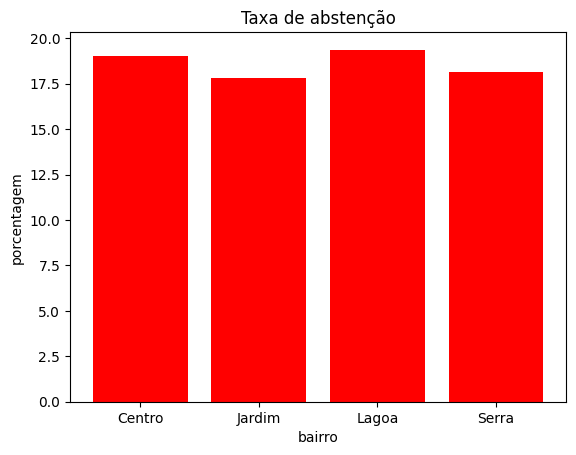

In [115]:
abstencao_taxa = df_copy.groupby("bairro")[["eleitores_aptos","abstencoes"]].sum()
abstencao_taxa["taxa_abstencao"] = (abstencao_taxa['abstencoes'] / abstencao_taxa['eleitores_aptos']) * 100
categorias = []
vendas = []
for i in range(len(abstencao_taxa)):
  c = abstencao_taxa["taxa_abstencao"]
  c = c.iloc[i]
  d = abstencao_taxa.index[i]
  vendas.append(c)
  categorias.append(d)


plt.bar(categorias, vendas, color='red')

plt.title('Taxa de abstenção')
plt.xlabel('bairro')
plt.ylabel('porcentagem')

plt.show()


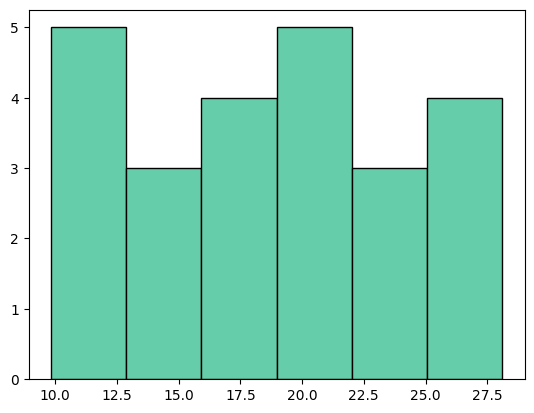

In [116]:
dados = []
df_secoes = df_copy[["secao", "taxa_abstencao"]].copy()

for i in range(len(df_secoes)):
  c = df_secoes["taxa_abstencao"]
  c = c.iloc[i]
  dados.append(c)

plt.hist(dados, bins=6, color='mediumaquamarine', edgecolor='black')

# Exibindo o gráfico
plt.show()





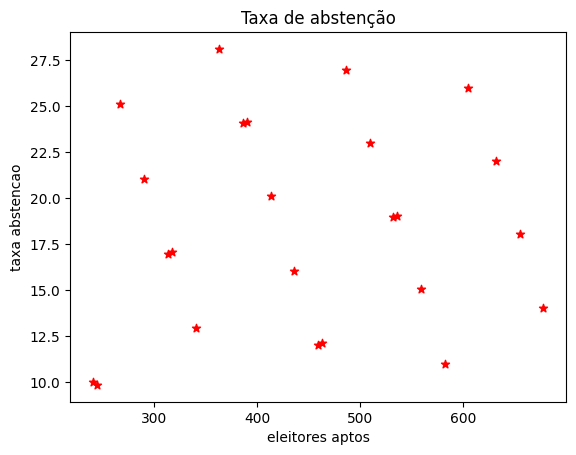

In [117]:
df_dispersao = df_copy[["eleitores_aptos", "taxa_abstencao"]].copy()
dados_x = []
dados_y = []
for i in range(len(df_dispersao)):
  c = df_dispersao["eleitores_aptos"]
  c = c.iloc[i]
  dados_x.append(c)

for i in range(len(df_dispersao)):
  c = df_dispersao["taxa_abstencao"]
  c = c.iloc[i]
  dados_y.append(c)
plt.title('Taxa de abstenção')
plt.xlabel('eleitores aptos')
plt.ylabel('taxa abstencao')
plt.scatter(dados_x, dados_y, c='red', marker='*')

plt.savefig('Taxa_de_abstenção.png', dpi=300, bbox_inches='tight')
